# 8413GA1 — k-NN booster classification

**Business objective.** Help the Public Health Agency of Canada (PHAC) decide where and how to focus COVID-19 booster outreach and access support. The analysis (1) identifies respondent groups with lower reported booster uptake, (2) summarizes the barriers reported by vaccinated respondents without a booster, and (3) builds a k-NN classifier that ranks respondents by their likelihood of not having a booster, so that limited outreach capacity can be directed where it is most needed.

**Target.** `vac_boost_1`: whether the respondent received a COVID-19 booster or third dose (Yes / No). The class of interest for outreach is **No**.

**Workflow.**
1. Data preparation: cleaning, target definition, data-quality checks, predictor eligibility and leakage controls
2. Exploratory data analysis: which groups report lower booster uptake
3. Reported barriers among vaccinated respondents without a booster
4. Seeded train/test split
5. Model tuning: training-only nested cross-validation and a 5-fold grid search
6. Choosing k: training versus cross-validated ROC-AUC
7. Outreach capacity threshold
8. Final locked-model test evaluation
9. Who the outreach list reaches

In [1]:
from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
    validation_curve,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

SEED = 20261110
DATA_FILE = Path("COVID-19BehaviorData_CAN2022.csv")

# scikit-learn 1.8 replaced penalty="l1" with l1_ratio=1.0.
SKLEARN_VERSION = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
L1_PENALTY = {"l1_ratio": 1.0} if SKLEARN_VERSION >= (1, 8) else {"penalty": "l1"}

NUMERIC_PREDICTORS = ["age", "cantril_ladder", "i2_health"]
AGE_BINS = [17, 29, 39, 49, 59, 69, 120]
AGE_LABELS = ["18–29", "30–39", "40–49", "50–59", "60–69", "70+"]
STATUS_ORDER = ["Boosted", "Vaccinated, no booster", "Never vaccinated"]
STATUS_COLORS = {
    "Boosted": "#2a78d6",
    "Vaccinated, no booster": "#1baf7a",
    "Never vaccinated": "#eb6834",
}
PRIMARY_COLOR = "#2a78d6"
SECONDARY_COLOR = "#eb6834"

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.2,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})
pd.set_option("display.width", 160)

In [2]:
if not DATA_FILE.exists():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            f"Put {DATA_FILE.name} in the same folder as this notebook, then run again."
        ) from exc
    print(f"Upload {DATA_FILE.name} to the Colab runtime.")
    uploaded = files.upload()
    if DATA_FILE.name not in uploaded:
        raise FileNotFoundError(f"Upload the file named {DATA_FILE.name} to continue.")

data = pd.read_csv(DATA_FILE, low_memory=False)
print(f"Original shape: {data.shape[0]:,} rows × {data.shape[1]:,} columns")

Original shape: 6,430 rows × 512 columns


## 1. Data preparation

### 1.1 Cleaning and target definition

Convert whitespace and `__NA__` to missing values, then remove only columns that are empty for all respondents with `cleaned_data = data.dropna(axis=1, how="all").copy()`. Partially answered columns are preserved.

The 644 skipped booster responses all belong to respondents with neither a first nor a second dose. Their target value is inferred as `No` for the binary model target. For reporting, a three-level booster status keeps these never-vaccinated respondents separate from vaccinated respondents who reported no booster, because the two groups call for different interventions: building vaccine confidence versus completing the vaccine series. In this dataset there are 644 never-vaccinated respondents, 2,140 vaccinated respondents reporting no booster, and 3,646 reporting a booster. The classes are moderately imbalanced (about 57% Yes, 43% No), so no resampling is required; stratified splits keep the class mix stable.

In [3]:
text_columns = data.select_dtypes(include=["object", "string"]).columns
data[text_columns] = data[text_columns].replace(r"^\s*$", pd.NA, regex=True)
data[text_columns] = data[text_columns].replace("__NA__", pd.NA)
cleaned_data = data.dropna(axis=1, how="all").copy()

original_booster_response = cleaned_data["vac_boost_1"].copy()
skipped_target = original_booster_response.isna()
assert skipped_target.sum() == 644
assert (cleaned_data.loc[skipped_target, "vac"] == "No, neither").all()
cleaned_data["vac_boost_1"] = original_booster_response.fillna("No")
cleaned_data = cleaned_data.where(cleaned_data.notna(), np.nan)

booster_status = pd.Series(
    np.select(
        [skipped_target.to_numpy(), original_booster_response.eq("Yes").to_numpy()],
        ["Never vaccinated", "Boosted"],
        default="Vaccinated, no booster",
    ),
    index=cleaned_data.index,
    name="booster_status",
)
status_counts = booster_status.value_counts().reindex(STATUS_ORDER)
assert status_counts.sum() == len(cleaned_data)

print(f"Nonempty-column shape: {cleaned_data.shape[0]:,} rows × {cleaned_data.shape[1]:,} columns")
print("\nBinary model target (vac_boost_1):")
print(cleaned_data["vac_boost_1"].value_counts().to_string())
print("\nThree-level booster status (reporting only; the model target remains binary):")
print(status_counts.to_string())

Nonempty-column shape: 6,430 rows × 159 columns

Binary model target (vac_boost_1):
vac_boost_1
Yes    3646
No     2784

Three-level booster status (reporting only; the model target remains binary):
booster_status
Boosted                   3646
Vaccinated, no booster    2140
Never vaccinated           644


### 1.2 Data-quality checks and numeric predictors

Check for duplicate respondents and implausible values in the three numeric predictors: age, the 0–10 life-satisfaction ladder (`cantril_ladder`), and the number of close contacts outside the household (`i2_health`). The close-contact count is stored as text and is highly right-skewed, with a few respondents reporting up to 1,000 contacts. Because k-NN relies on distances, such extreme values would compress everyone else into a narrow band of the scaled variable, so the count is converted to numeric and log-transformed as log(1 + contacts). This fixed transformation uses no information from other respondents and therefore cannot leak test-set information. All other predictors are categorical survey responses.

In [4]:
cleaned_data["i2_health"] = pd.to_numeric(cleaned_data["i2_health"], errors="coerce")

print(f"Duplicate respondent IDs: {cleaned_data['RecordNo'].duplicated().sum()}")
print(f"Duplicate response rows (ignoring ID): {cleaned_data.drop(columns='RecordNo').duplicated().sum()}")

numeric_profile = cleaned_data[NUMERIC_PREDICTORS].describe(percentiles=[0.5, 0.99]).T
numeric_profile["missing_n"] = cleaned_data[NUMERIC_PREDICTORS].isna().sum()
numeric_profile["skewness"] = cleaned_data[NUMERIC_PREDICTORS].skew()
print("\nNumeric predictors before transformation:")
print(numeric_profile.round(2).to_string())

cleaned_data["i2_health"] = np.log1p(cleaned_data["i2_health"])
print(f"\nSkewness of log(1 + close contacts): {cleaned_data['i2_health'].skew():.2f}")

Duplicate respondent IDs: 0
Duplicate response rows (ignoring ID): 0

Numeric predictors before transformation:
                 count   mean    std   min   50%     99%     max  missing_n  skewness
age             6430.0  49.80  18.07  18.0  50.0   82.71    90.0          0     -0.05
cantril_ladder  6430.0   6.20   2.15   0.0   7.0   10.00    10.0          0     -0.68
i2_health       4423.0  17.25  77.16   0.0   3.0  300.00  1000.0       2007     10.32

Skewness of log(1 + close contacts): 0.99


### 1.3 Predictor eligibility and leakage controls

**Reconciling the 101 versus 85 missing-column counts.** After restoring all 6,430 respondents, 101 columns contain missing values. Sixteen of them have no observations among respondents who directly answered the booster question; they are reasons asked only of people with neither first nor second dose. These columns are structurally tied to the target construction and are excluded. The remaining count is exactly 85.

In [5]:
columns_with_missing = [name for name in cleaned_data if cleaned_data[name].isna().any()]
direct_booster_answer = original_booster_response.notna()
never_vaccinated_branch = [
    name for name in columns_with_missing
    if cleaned_data.loc[direct_booster_answer, name].notna().sum() == 0
]
missing_85 = [name for name in columns_with_missing if name not in never_vaccinated_branch]

print(f"Columns with missing values: {len(columns_with_missing)}")
print(f"Excluded never-vaccinated branch: {len(never_vaccinated_branch)}")
print(f"Model 2 missing-column pool: {len(missing_85)}")
assert len(columns_with_missing) == 101
assert len(never_vaccinated_branch) == 16
assert len(missing_85) == 85
print("\nExcluded 16 columns:")
print(never_vaccinated_branch)

Columns with missing values: 101
Excluded never-vaccinated branch: 16
Model 2 missing-column pool: 85

Excluded 16 columns:
['vac_1', 'vac12_1', 'vac12_2', 'vac12_3', 'vac12_4', 'vac12_11', 'vac12_5', 'vac12_6', 'vac12_7', 'vac12_8', 'vac12_9', 'vac12_10', 'vac12_96', 'vac12_other', 'vac12_12', 'vac12_13']


           variable  missing_n  missing_pct  observed_levels
          Soc2_open       6297         97.9              103
            q_other       6191         96.3              206
vac12_booster_other       6046         94.0              370
   i14_health_other       5929         92.2              358
         long_covid       5635         87.6                5
              WAH_2       5493         85.4                5
              WAH_1       5493         85.4                5
              WAH_3       5493         85.4                5
             Soc2_1       5469         85.1                2
             Soc2_2       5469         85.1                2
             Soc2_3       5469         85.1                2
             Soc2_4       5469         85.1                2
             Soc2_5       5469         85.1                2
             Soc2_6       5469         85.1                2
          had_covid       5459         84.9                2
           future_3     

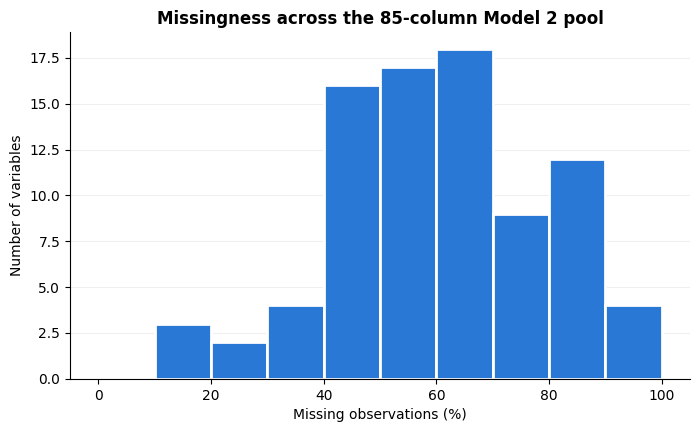

In [6]:
missing_summary = pd.DataFrame({
    "variable": missing_85,
    "missing_n": [cleaned_data[name].isna().sum() for name in missing_85],
    "missing_pct": [cleaned_data[name].isna().mean() * 100 for name in missing_85],
    "observed_levels": [cleaned_data[name].nunique(dropna=True) for name in missing_85],
}).sort_values("missing_pct", ascending=False)
print(missing_summary.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(missing_summary["missing_pct"], bins=np.arange(0, 105, 10), color=PRIMARY_COLOR, edgecolor="white", linewidth=2)
ax.set(
    title="Missingness across the 85-column Model 2 pool",
    xlabel="Missing observations (%)",
    ylabel="Number of variables",
)
ax.grid(axis="x", visible=False)
plt.show()

**Target leakage and free-text fields.** Booster follow-up questions are asked conditionally based on booster status, so their presence or absence reveals the target. Free-text responses have very high cardinality and cannot be meaningfully represented as ordinary categories for k-NN. Both groups are excluded before screening. The booster barrier items are analyzed descriptively in Section 3 only.

**Complete predictor pool.** Of the 58 complete columns, six are not used as predictors: the target itself, the respondent ID, the interview timestamp (survey timing is represented by `qweek`), the survey sampling weight, first/second-dose status `vac` (it determines the target for every never-vaccinated respondent), and `WCRex1` (opinion of the government's handling of COVID-19, excluded so that outreach prioritization does not depend on political views). The remaining 52 complete predictors form the complete pool; adding the eligible partially missing predictors gives the expanded pool. Missing responses in the expanded pool are handled inside the model pipeline (Section 5).

In [7]:
booster_followup_columns = [
    name for name in missing_85
    if ("boost" in name.lower() and name != "vac_boost_1")
]
free_text_columns = [
    name for name in ["i14_health_other", "Soc2_open", "q_other"]
    if name in missing_85
]
excluded_model2_columns = sorted(set(booster_followup_columns + free_text_columns))
eligible_missing_predictors = [
    name for name in missing_85 if name not in excluded_model2_columns
]

print(f"Booster follow-up leakage columns excluded: {len(booster_followup_columns)}")
print(booster_followup_columns)
print(f"\nFree-text columns excluded: {len(free_text_columns)}")
print(free_text_columns)
print(f"\nEligible missing-value predictors: {len(eligible_missing_predictors)}")

Booster follow-up leakage columns excluded: 14
['vac_boost_2', 'vac12_booster_1', 'vac12_booster_2', 'vac12_booster_3', 'vac12_booster_4', 'vac12_booster_5', 'vac12_booster_6', 'vac12_booster_7', 'vac12_booster_8', 'vac12_booster_9', 'vac12_booster_10', 'vac12_booster_96', 'vac12_booster_other', 'vac_boost_beyond']

Free-text columns excluded: 3
['i14_health_other', 'Soc2_open', 'q_other']

Eligible missing-value predictors: 68


In [8]:
complete_table = cleaned_data.dropna(axis=1, how="any")
assert complete_table.shape[1] == 58
excluded_complete_fields = {
    "vac_boost_1": "Target variable",
    "RecordNo": "Respondent identifier",
    "endtime": "Interview timestamp (survey timing is captured by qweek)",
    "weight": "Survey sampling weight, not a respondent characteristic",
    "vac": "First/second-dose status; determines the target for never-vaccinated respondents",
    "WCRex1": "Opinion of government handling; not used to prioritize outreach",
}
complete_candidates = [
    name for name in complete_table.columns if name not in excluded_complete_fields
]
assert len(complete_candidates) == 52
expanded_candidates = list(dict.fromkeys(complete_candidates + eligible_missing_predictors))

print("Complete columns not used as predictors:")
print(pd.Series(excluded_complete_fields, name="reason").rename_axis("column").to_string())

variable_funnel = pd.Series({
    "Columns in the original file": data.shape[1],
    "Columns with at least one response": cleaned_data.shape[1],
    "Complete columns": complete_table.shape[1],
    "Complete candidate predictors": len(complete_candidates),
    "Columns with missing values": len(columns_with_missing),
    "Missing-value columns outside the never-vaccinated branch": len(missing_85),
    "Eligible missing-value predictors": len(eligible_missing_predictors),
    "Expanded candidate predictors": len(expanded_candidates),
}, name="columns")
print("\nVariable funnel:")
print(variable_funnel.to_string())

Complete columns not used as predictors:
column
vac_boost_1                                      Target variable
RecordNo                                   Respondent identifier
endtime        Interview timestamp (survey timing is captured...
weight         Survey sampling weight, not a respondent chara...
vac            First/second-dose status; determines the targe...
WCRex1         Opinion of government handling; not used to pr...

Variable funnel:
Columns in the original file                                 512
Columns with at least one response                           159
Complete columns                                              58
Complete candidate predictors                                 52
Columns with missing values                                  101
Missing-value columns outside the never-vaccinated branch     85
Eligible missing-value predictors                             68
Expanded candidate predictors                                120


## 2. Exploratory data analysis: which groups report lower booster uptake?

The EDA follows the mandate: it asks which respondent groups report lower booster uptake and whether their gap is mainly among never-vaccinated respondents (a vaccine-confidence problem) or among vaccinated respondents without a booster (a series-completion and access problem). Results use the full survey for descriptive reporting only and are unweighted respondent counts. All variable selection and hyperparameter tuning below use training data only.

**2.1 Target distribution.** Share of respondents in each booster status.

                           n  percent model_target
booster_status                                    
Boosted                 3646     56.7          Yes
Vaccinated, no booster  2140     33.3           No
Never vaccinated         644     10.0           No


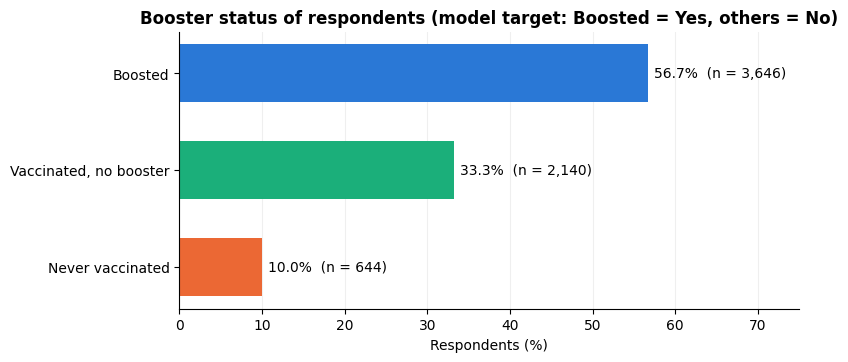

In [9]:
eda = cleaned_data.copy()
eda["booster_status"] = booster_status
eda["booster_yes"] = eda["vac_boost_1"].eq("Yes")
eda["age_group"] = pd.cut(eda["age"], bins=AGE_BINS, labels=AGE_LABELS)
eda["province"] = eda["region"].str.split(" / ").str[0]

target_table = status_counts.to_frame("n")
target_table["percent"] = target_table["n"] / len(eda) * 100
target_table["model_target"] = ["Yes", "No", "No"]
print(target_table.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(
    target_table.index,
    target_table["percent"],
    color=[STATUS_COLORS[status] for status in target_table.index],
    height=0.6,
)
ax.bar_label(
    bars,
    labels=[f"{pct:.1f}%  (n = {n:,})" for pct, n in zip(target_table["percent"], target_table["n"])],
    padding=4,
)
ax.invert_yaxis()
ax.set(
    title="Booster status of respondents (model target: Boosted = Yes, others = No)",
    xlabel="Respondents (%)",
    xlim=(0, 75),
)
ax.grid(axis="y", visible=False)
plt.show()

**2.2 Which predictors are most strongly related to booster uptake?** For every complete candidate predictor, booster uptake is computed within each answer category with at least 50 respondents (age in groups), and the predictor is ranked by the gap between its highest and lowest category in percentage points. This screening is descriptive only; the model's own predictor selection is training-only (Section 5).

             variable                                                       label  uptake_gap_pp lowest_uptake_category  lowest_uptake_pct highest_uptake_category  highest_uptake_pct
0                vac7                                  Trust in COVID-19 vaccines           73.7             Not at all                8.1               Very much                81.7
1                r1_8                          Believes a vaccine will protect me           64.1           1 – Disagree               12.3               7 - Agree                76.5
2                r1_9                      Believes a vaccine will protect others           61.5           1 – Disagree               14.5               7 - Agree                76.0
3              vac2_3  Expects health authorities to provide an effective vaccine           51.4  5 – Strongly disagree               22.1      1 - Strongly agree                73.5
4                 age                                                   Age group    

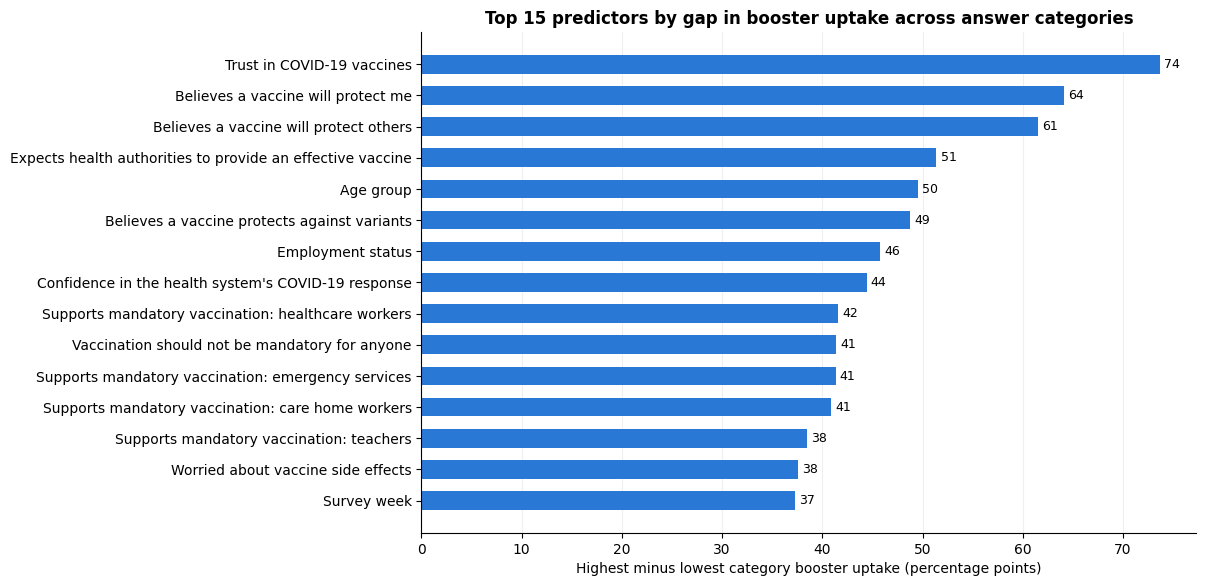

In [10]:
PREDICTOR_LABELS = {
    "vac7": "Trust in COVID-19 vaccines",
    "r1_8": "Believes a vaccine will protect me",
    "r1_9": "Believes a vaccine will protect others",
    "vac2_3": "Expects health authorities to provide an effective vaccine",
    "age": "Age group",
    "vac2_7": "Believes a vaccine protects against variants",
    "employment_status": "Employment status",
    "WCRex2": "Confidence in the health system's COVID-19 response",
    "vac_man_1": "Supports mandatory vaccination: healthcare workers",
    "vac_man_99": "Vaccination should not be mandatory for anyone",
    "vac_man_3": "Supports mandatory vaccination: emergency services",
    "vac_man_2": "Supports mandatory vaccination: care home workers",
    "vac_man_4": "Supports mandatory vaccination: teachers",
    "vac2_2": "Worried about vaccine side effects",
    "qweek": "Survey week",
    "cantril_ladder": "Life satisfaction (0–10)",
    "r1_1": "Believes COVID-19 is very dangerous for me",
    "i12_health_4": "Covers nose and mouth when sneezing or coughing",
    "i12_health_22": "Wears a face mask inside grocery stores",
    "household_size": "Household size",
    "household_children": "Children under 18 in household",
    "region": "Province or territory",
    "gender": "Gender",
}

MIN_CATEGORY_N = 50
association_rows = []
for name in complete_candidates:
    groups = eda["age_group"] if name == "age" else eda[name].astype(str)
    category_rates = eda.groupby(groups, observed=True)["booster_yes"].agg(["mean", "size"])
    category_rates = category_rates[category_rates["size"] >= MIN_CATEGORY_N]
    association_rows.append({
        "variable": name,
        "label": PREDICTOR_LABELS.get(name, name),
        "uptake_gap_pp": (category_rates["mean"].max() - category_rates["mean"].min()) * 100,
        "lowest_uptake_category": category_rates["mean"].idxmin(),
        "lowest_uptake_pct": category_rates["mean"].min() * 100,
        "highest_uptake_category": category_rates["mean"].idxmax(),
        "highest_uptake_pct": category_rates["mean"].max() * 100,
    })
predictor_association = (
    pd.DataFrame(association_rows)
    .sort_values("uptake_gap_pp", ascending=False)
    .reset_index(drop=True)
)
print(predictor_association.head(20).round(1).to_string())

top_associations = predictor_association.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
bars = ax.barh(top_associations["label"], top_associations["uptake_gap_pp"], color=PRIMARY_COLOR, height=0.6)
ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
ax.set(
    title="Top 15 predictors by gap in booster uptake across answer categories",
    xlabel="Highest minus lowest category booster uptake (percentage points)",
)
ax.grid(axis="y", visible=False)
plt.show()

**2.3 Booster status by respondent group.** Normalized stacked bars show, for each group, the share boosted, vaccinated without a booster, and never vaccinated. Groups with fewer than 30 respondents are not shown. Survey week is included because it captures the booster rollout over time; a random train/test split may therefore be more optimistic than validation on a future period.

Booster status by group (% of respondents in each category):
booster_status                                             n  Boosted  Vaccinated, no booster  Never vaccinated
grouping                       category                                                                        
Age group                      18–29                    1112     35.1                    53.7              11.2
                               30–39                    1063     40.7                    45.6              13.6
                               40–49                     940     46.2                    40.9              13.0
                               50–59                     986     57.9                    31.0              11.1
                               60–69                    1213     72.1                    20.7               7.3
                               70+                      1116     84.6                    10.5               4.9
Employment status              Unemployed  

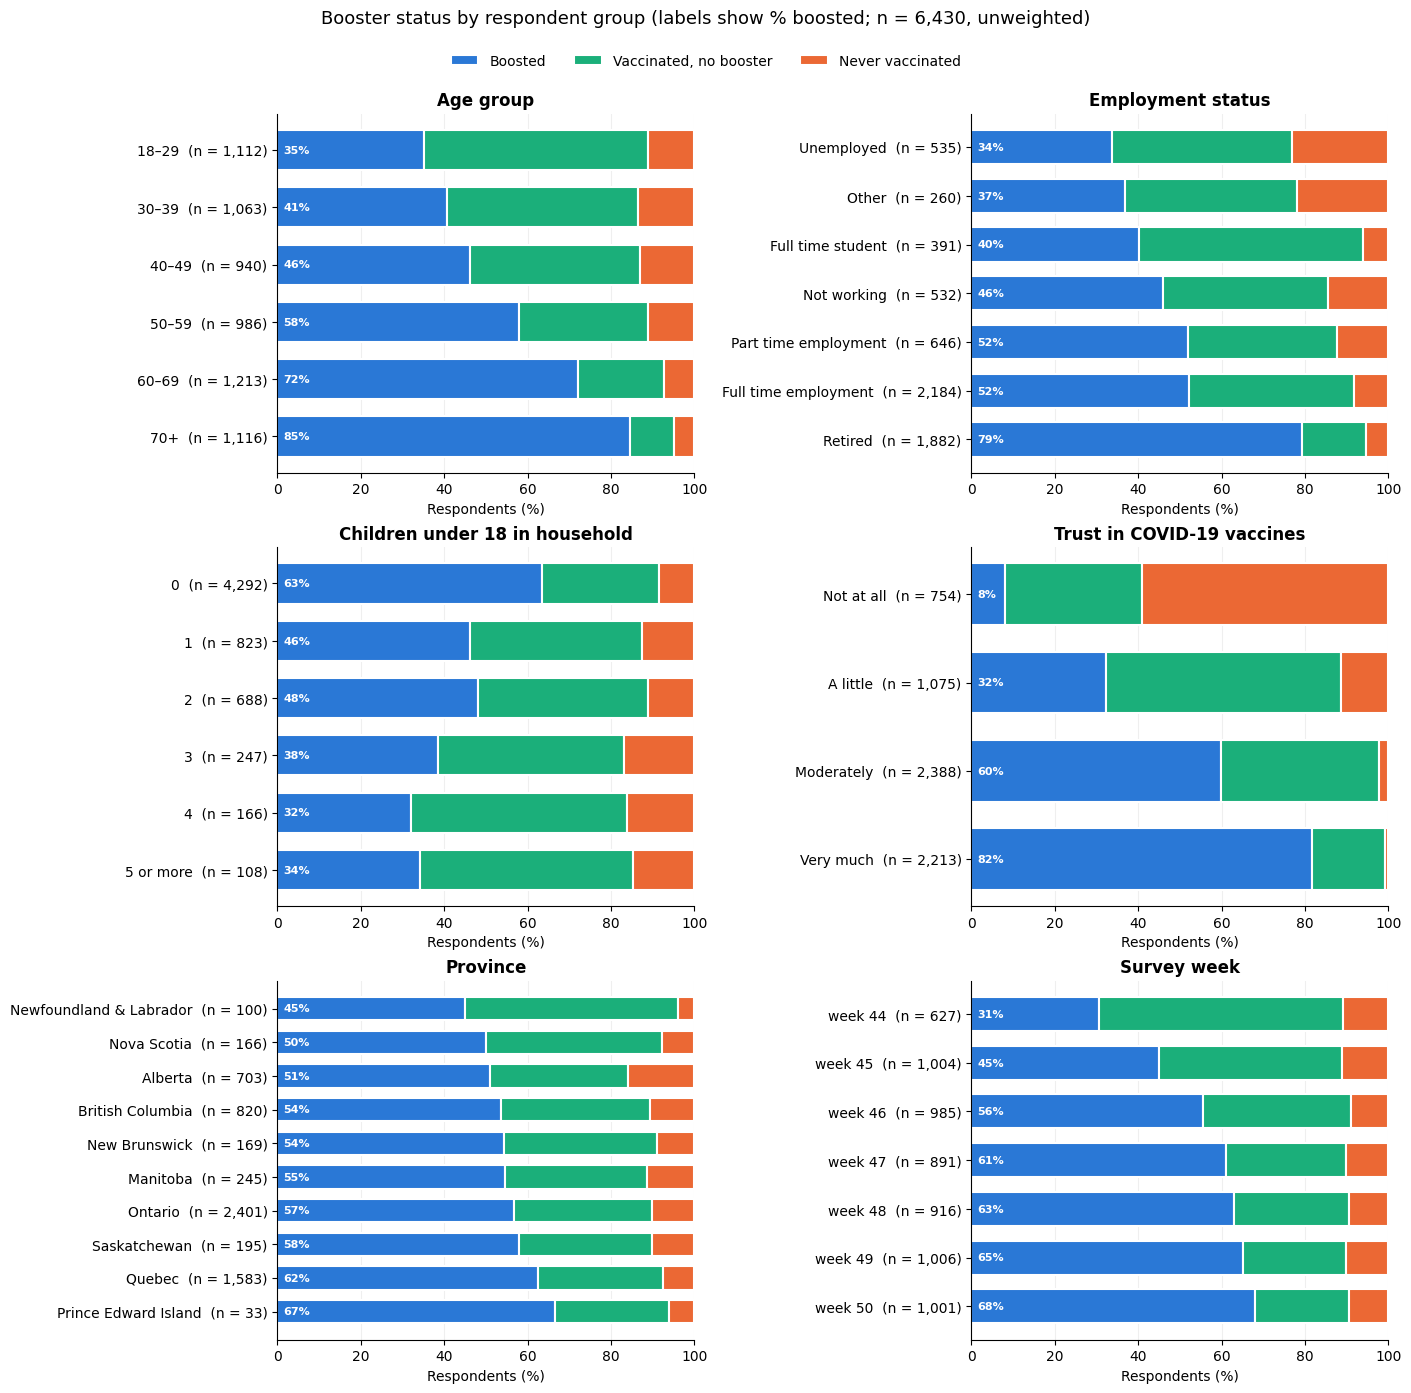

In [11]:
def status_breakdown(group, order=None, min_n=30):
    counts = pd.crosstab(eda[group], eda["booster_status"]).reindex(columns=STATUS_ORDER, fill_value=0)
    counts = counts[counts.sum(axis=1) >= min_n]
    if order is None:
        counts = counts.loc[(counts["Boosted"] / counts.sum(axis=1)).sort_values().index]
    else:
        counts = counts.reindex([level for level in order if level in counts.index])
    shares = counts.div(counts.sum(axis=1), axis=0) * 100
    shares.insert(0, "n", counts.sum(axis=1))
    return shares


def plot_status_bars(ax, shares, title):
    labels = [f"{level}  (n = {n:,})" for level, n in zip(shares.index.astype(str), shares["n"])]
    left = np.zeros(len(shares))
    for status in STATUS_ORDER:
        values = shares[status].to_numpy()
        ax.barh(labels, values, left=left, color=STATUS_COLORS[status], edgecolor="white", linewidth=1.5, height=0.7, label=status)
        left += values
    for row, value in enumerate(shares["Boosted"]):
        ax.text(1.5, row, f"{value:.0f}%", va="center", ha="left", color="white", fontsize=8, fontweight="bold")
    ax.invert_yaxis()
    ax.set(title=title, xlim=(0, 100), xlabel="Respondents (%)")
    ax.grid(axis="y", visible=False)


group_views = [
    ("age_group", AGE_LABELS, "Age group"),
    ("employment_status", None, "Employment status"),
    ("household_children", ["0", "1", "2", "3", "4", "5 or more"], "Children under 18 in household"),
    ("vac7", ["Not at all", "A little", "Moderately", "Very much"], "Trust in COVID-19 vaccines"),
    ("province", None, "Province"),
    ("qweek", [f"week {number}" for number in range(44, 51)], "Survey week"),
]
group_tables = {}
for group, order, title in group_views:
    group_tables[title] = status_breakdown(group, order)

group_summary = pd.concat(group_tables, names=["grouping", "category"])
print("Booster status by group (% of respondents in each category):")
print(group_summary.round(1).to_string())

fig, axes = plt.subplots(3, 2, figsize=(14, 13), constrained_layout=True)
for ax, (title, shares) in zip(axes.flat, group_tables.items()):
    plot_status_bars(ax, shares, title)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.035))
fig.suptitle("Booster status by respondent group (labels show % boosted; n = 6,430, unweighted)", fontsize=13, y=1.06)
plt.show()

The EDA is descriptive rather than causal. Groups with low uptake that consist mostly of vaccinated respondents without a booster are candidates for reminders and access support, whereas groups with a large never-vaccinated share point to confidence-building communication.

## 3. Reported barriers among vaccinated respondents without a booster

The barrier items are analyzed descriptively only among the 2,140 respondents who directly reported no booster; they are not model predictors because they are asked conditionally on booster status. Respondents could select several barriers, so item percentages use each question's answered responses as the denominator and need not sum to 100%.

                  n_answered  n_selected  percent_selected
vac12_booster_7         2140         554              25.9
vac12_booster_5         2140         499              23.3
vac12_booster_1         2140         474              22.1
vac12_booster_96        2140         386              18.0
vac12_booster_3         2140         385              18.0
vac12_booster_6         2140         376              17.6
vac12_booster_9         2140         266              12.4
vac12_booster_8         2140         143               6.7
vac12_booster_2         2140          72               3.4
vac12_booster_10        2140          55               2.6
vac12_booster_4         2140          42               2.0


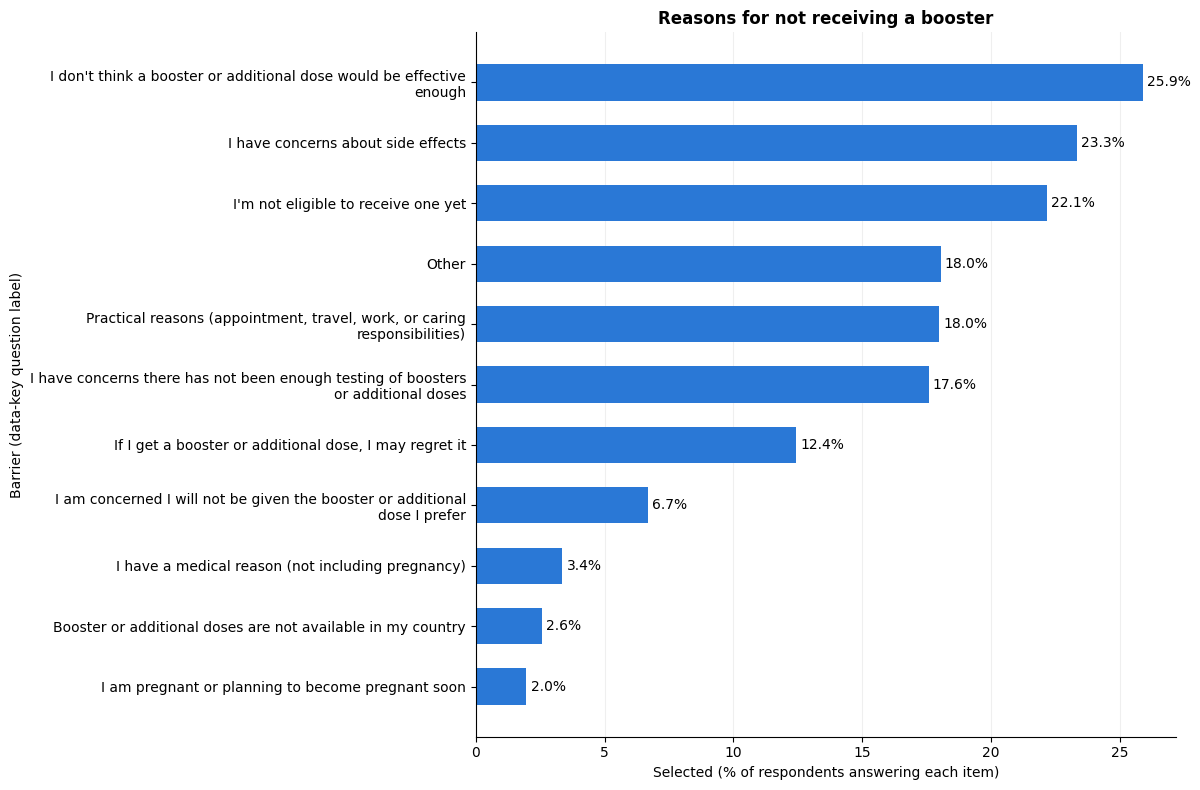

In [12]:
barrier_data = cleaned_data.loc[original_booster_response.eq("No")].copy()
assert len(barrier_data) == 2140

barrier_columns = [
    col for col in cleaned_data.columns
    if col.startswith("vac12_booster_")
    and col != "vac12_booster_other"
]

answered = barrier_data[barrier_columns].isin(["Yes", "No"]).sum()
selected = barrier_data[barrier_columns].eq("Yes").sum()

barrier_table = pd.DataFrame({
    "n_answered": answered,
    "n_selected": selected,
    "percent_selected": (
        100 * selected / answered.replace(0, np.nan)
    ),
}).sort_values("percent_selected", ascending=False)

print(barrier_table.round(1))

barrier_labels = {
    "vac12_booster_1": "I'm not eligible to receive one yet",
    "vac12_booster_2": "I have a medical reason (not including pregnancy)",
    "vac12_booster_3": "Practical reasons (appointment, travel, work, or caring responsibilities)",
    "vac12_booster_4": "I am pregnant or planning to become pregnant soon",
    "vac12_booster_5": "I have concerns about side effects",
    "vac12_booster_6": "I have concerns there has not been enough testing of boosters or additional doses",
    "vac12_booster_7": "I don't think a booster or additional dose would be effective enough",
    "vac12_booster_8": "I am concerned I will not be given the booster or additional dose I prefer",
    "vac12_booster_9": "If I get a booster or additional dose, I may regret it",
    "vac12_booster_10": "Booster or additional doses are not available in my country",
    "vac12_booster_96": "Other",
}
assert set(barrier_columns) <= barrier_labels.keys()

barrier_plot = barrier_table.rename(index=barrier_labels)
display_labels = [textwrap.fill(label, width=62) for label in barrier_plot.index]
fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(display_labels, barrier_plot["percent_selected"], color=PRIMARY_COLOR, height=0.6)
ax.invert_yaxis()
ax.set(
    title="Reasons for not receiving a booster",
    xlabel="Selected (% of respondents answering each item)",
    ylabel="Barrier (data-key question label)",
)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

**Barrier themes and intervention type.** To translate barriers into initiatives, the items are grouped into three themes. *Access or eligibility* barriers (not yet eligible, practical difficulties, not available) call for access support such as eligibility reminders, extended hours, walk-in and mobile clinics. *Confidence or information* barriers (side effects, insufficient testing, doubts about effectiveness, product preference, anticipated regret) call for targeted communication. *Medical or pregnancy* reasons call for clinical guidance through healthcare providers. A respondent counts toward a theme if they selected at least one of its items, so a respondent can count toward several themes.

Share citing at least one barrier in each theme (% of vaccinated respondents without a booster):
Access or eligibility        40.7
Confidence or information    51.2
Medical or pregnancy          5.3

By age group:
             n  Access or eligibility  Confidence or information  Medical or pregnancy
age_group                                                                             
18–29      597                   50.9                       52.6                   6.9
30–39      485                   36.7                       60.2                   9.9
40–49      384                   39.1                       47.1                   3.6
50–59      306                   37.6                       47.4                   1.6
60–69      251                   33.9                       39.0                   2.0
70+        117                   32.5                       55.6                   0.0

By province (provinces with at least 30 respondents):
                           n  Acces

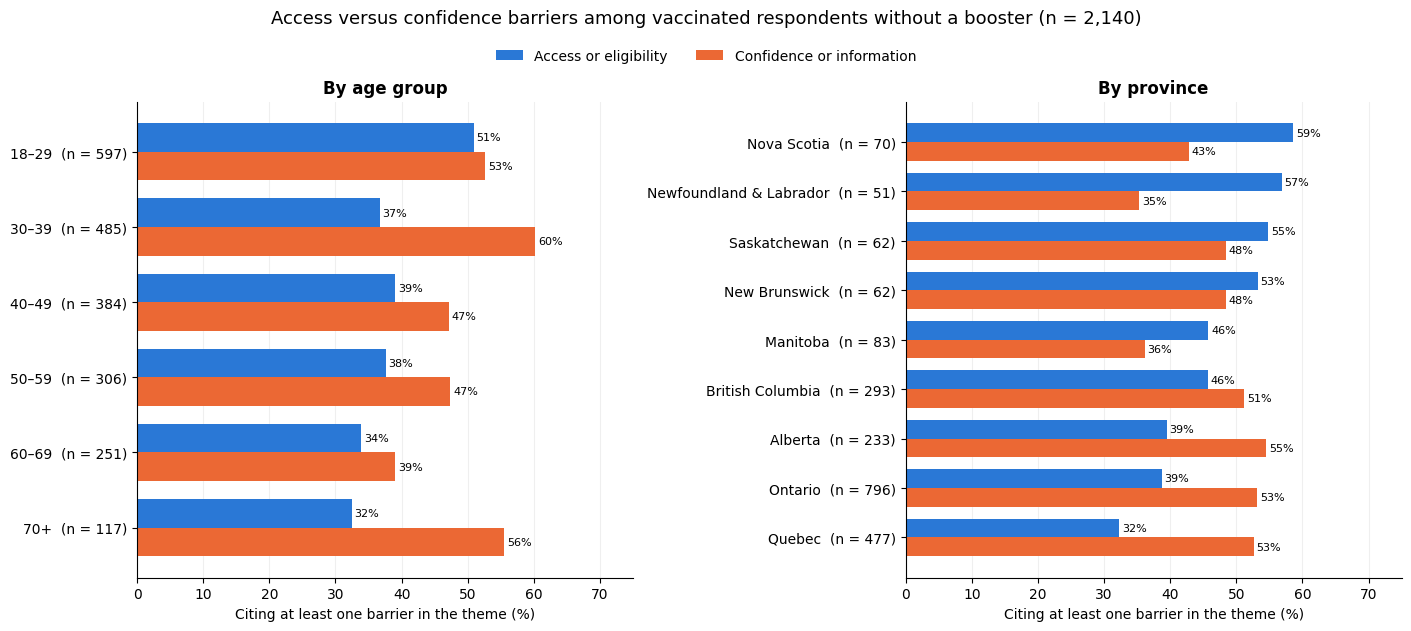

In [13]:
BARRIER_THEMES = {
    "Access or eligibility": ["vac12_booster_1", "vac12_booster_3", "vac12_booster_10"],
    "Confidence or information": [
        "vac12_booster_5", "vac12_booster_6", "vac12_booster_7", "vac12_booster_8", "vac12_booster_9",
    ],
    "Medical or pregnancy": ["vac12_booster_2", "vac12_booster_4"],
}
theme_flags = pd.DataFrame({
    theme: barrier_data[columns].eq("Yes").any(axis=1)
    for theme, columns in BARRIER_THEMES.items()
})
theme_flags["age_group"] = pd.cut(barrier_data["age"], bins=AGE_BINS, labels=AGE_LABELS)
theme_flags["province"] = barrier_data["region"].str.split(" / ").str[0]
theme_names = list(BARRIER_THEMES)


def theme_shares(group, min_n=30):
    table = theme_flags.groupby(group, observed=True)[theme_names].mean() * 100
    table.insert(0, "n", theme_flags.groupby(group, observed=True).size())
    return table[table["n"] >= min_n]


print("Share citing at least one barrier in each theme (% of vaccinated respondents without a booster):")
print((theme_flags[theme_names].mean() * 100).round(1).to_string())
theme_by_age = theme_shares("age_group")
theme_by_province = theme_shares("province").sort_values("Access or eligibility", ascending=False)
print("\nBy age group:")
print(theme_by_age.round(1).to_string())
print("\nBy province (provinces with at least 30 respondents):")
print(theme_by_province.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
theme_colors = {"Access or eligibility": PRIMARY_COLOR, "Confidence or information": SECONDARY_COLOR}
for ax, table, title in [
    (axes[0], theme_by_age, "By age group"),
    (axes[1], theme_by_province, "By province"),
]:
    labels = [f"{level}  (n = {n:,})" for level, n in zip(table.index.astype(str), table["n"])]
    positions = np.arange(len(table))
    bar_height = 0.38
    for offset, theme in [(-bar_height / 2, "Access or eligibility"), (bar_height / 2, "Confidence or information")]:
        bars = ax.barh(positions + offset, table[theme], height=bar_height, color=theme_colors[theme], label=theme)
        ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=8)
    ax.set_yticks(positions, labels)
    ax.invert_yaxis()
    ax.set(title=title, xlabel="Citing at least one barrier in the theme (%)", xlim=(0, 75))
    ax.grid(axis="y", visible=False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.07))
fig.suptitle("Access versus confidence barriers among vaccinated respondents without a booster (n = 2,140)", fontsize=13, y=1.12)
plt.show()

## 4. Create the seeded train/test split

Use `SEED = 20261110`, matching the final Model 1 development split. Model 2 screening and tuning use only the 70% training portion. The test portion remains unscored until Section 8.

In [14]:
train_data, test_data = train_test_split(
    cleaned_data,
    test_size=0.30,
    random_state=SEED,
    stratify=cleaned_data["vac_boost_1"],
)
y_train = train_data["vac_boost_1"].eq("Yes").astype(int)
print(f"Training set: {len(train_data):,} rows ({y_train.mean():.1%} boosted)")
print(f"Reserved test set: {len(test_data):,} rows — not scored")

Training set: 4,501 rows (56.7% boosted)
Reserved test set: 1,929 rows — not scored


## 5. Model tuning with training-only nested cross-validation

**Pipeline.** Every step that learns from data runs inside the pipeline, so it is fitted on training folds only:
- *Missing values.* Numeric predictors are imputed with the training median plus a missing-value indicator; categorical predictors receive an explicit "Not asked / missing" category, because many items were asked only in some survey weeks.
- *Encoding and scaling.* Categorical predictors are one-hot encoded with all k dummy columns, so no category acts as a baseline. Numeric predictors are min-max scaled to [0, 1], which puts them on the same scale as the 0/1 dummy columns so that no single variable dominates the distance.
- *Predictor selection.* k-NN uses every column in its distance, including irrelevant ones. An L1-penalized logistic regression keeps only encoded columns with non-zero coefficients before k-NN is fitted.
- *k-NN.* The grid tunes the number of neighbors k (odd values, so uniform votes between two classes cannot tie), vote weighting (uniform or inverse-distance), the distance metric (Manhattan or Euclidean), and the L1 strength C.

**Nested assessment.** Five outer folds evaluate a policy that chooses between the complete predictor pool and the expanded pool with eligible missing-value fields. Within each outer training fold, 3-fold inner CV selects the pool and settings; each outer fold stays untouched until it is scored. Pooled outer-fold predictions give an honest performance estimate and the out-of-fold probabilities used for the outreach threshold in Section 7.

**Final tuning.** After the assessment, the same grid is searched on the full training set with 5-fold CV to lock the pool and settings. ROC-AUC is the selection criterion because it measures how well the model ranks respondents by booster likelihood regardless of the cut-off; precision, recall and F1 for No describe the outreach tradeoff.

In [15]:
feature_pools = {
    "Complete predictor pool": complete_candidates,
    "Expanded eligible predictor pool": expanded_candidates,
}

scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision_no": make_scorer(precision_score, pos_label=0, zero_division=0),
    "recall_no": make_scorer(recall_score, pos_label=0, zero_division=0),
    "f1_no": make_scorer(f1_score, pos_label=0, zero_division=0),
}


def make_selection_knn_pipeline(features):
    numeric = [name for name in features if name in NUMERIC_PREDICTORS]
    categorical = [name for name in features if name not in numeric]
    numeric_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", MinMaxScaler()),
    ])
    categorical_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Not asked / missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    preprocessing = ColumnTransformer([
        ("numeric", numeric_steps, numeric),
        ("categorical", categorical_steps, categorical),
    ])
    selector = SelectFromModel(
        LogisticRegression(
            solver="liblinear",
            max_iter=3000,
            random_state=SEED,
            **L1_PENALTY,
        ),
        threshold=1e-8,
    )
    return Pipeline([
        ("preprocess", preprocessing),
        ("selector", selector),
        ("classifier", KNeighborsClassifier()),
    ])


K_GRID = [5, 15, 31, 41, 61, 81, 121]
selection_grid = {
    "selector__estimator__C": [0.1, 0.3],
    "classifier__n_neighbors": K_GRID,
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2],
}
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
tuning_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

X_train_pools = {
    name: train_data[features].copy()
    for name, features in feature_pools.items()
}
y_train_array = y_train.to_numpy()
n_candidates = int(np.prod([len(values) for values in selection_grid.values()]))
print(f"Candidate settings per predictor pool: {n_candidates}")
for name, features in feature_pools.items():
    print(f"{name}: {len(features)} input predictors")

Candidate settings per predictor pool: 56
Complete predictor pool: 52 input predictors
Expanded eligible predictor pool: 120 input predictors


In [16]:
outer_pool_probabilities = {
    name: np.full(len(y_train), np.nan)
    for name in feature_pools
}
nested_oof_probability = np.full(len(y_train), np.nan)
outer_fold_rows = []

for fold_number, (outer_train_idx, outer_valid_idx) in enumerate(outer_cv.split(train_data, y_train), start=1):
    fold_searches = {}
    for pool_name, X_pool in X_train_pools.items():
        search = GridSearchCV(
            make_selection_knn_pipeline(feature_pools[pool_name]),
            selection_grid,
            scoring=scoring,
            refit="roc_auc",
            cv=inner_cv,
            n_jobs=-1,
            error_score="raise",
        )
        search.fit(X_pool.iloc[outer_train_idx], y_train.iloc[outer_train_idx])
        fold_searches[pool_name] = search
        outer_pool_probabilities[pool_name][outer_valid_idx] = search.best_estimator_.predict_proba(
            X_pool.iloc[outer_valid_idx]
        )[:, 1]

    selected_pool = max(fold_searches, key=lambda name: fold_searches[name].best_score_)
    selected_search = fold_searches[selected_pool]
    nested_oof_probability[outer_valid_idx] = outer_pool_probabilities[selected_pool][outer_valid_idx]
    outer_fold_rows.append({
        "outer_fold": fold_number,
        "selected_pool": selected_pool,
        "selected_k": selected_search.best_params_["classifier__n_neighbors"],
        "selected_weights": selected_search.best_params_["classifier__weights"],
        "inner_best_ROC_AUC": selected_search.best_score_,
        "outer_ROC_AUC": roc_auc_score(
            y_train_array[outer_valid_idx], nested_oof_probability[outer_valid_idx]
        ),
    })

assert np.isfinite(nested_oof_probability).all()
assert all(np.isfinite(probabilities).all() for probabilities in outer_pool_probabilities.values())


def summarize_oof(y_true, probabilities, model_name, n_input_variables):
    predictions = (probabilities > 0.5).astype(int)
    return {
        "model": model_name,
        "input_predictor_variables": n_input_variables,
        "outer_OOF_ROC_AUC": roc_auc_score(y_true, probabilities),
        "outer_OOF_accuracy": accuracy_score(y_true, predictions),
        "outer_OOF_precision_No": precision_score(y_true, predictions, pos_label=0, zero_division=0),
        "outer_OOF_recall_No": recall_score(y_true, predictions, pos_label=0, zero_division=0),
        "outer_OOF_f1_No": f1_score(y_true, predictions, pos_label=0, zero_division=0),
    }


nested_pool_comparison = pd.DataFrame([
    summarize_oof(
        y_train_array,
        outer_pool_probabilities[pool_name],
        pool_name,
        len(feature_pools[pool_name]),
    )
    for pool_name in feature_pools
])
nested_policy_summary = summarize_oof(
    y_train_array, nested_oof_probability, "Nested pool-selection policy",
    int(np.mean([len(feature_pools[row["selected_pool"]]) for row in outer_fold_rows])),
)
final_training_comparison = pd.concat(
    [nested_pool_comparison, pd.DataFrame([nested_policy_summary])],
    ignore_index=True,
)
print("Nested outer-CV results (pooled out-of-fold predictions; not inner-CV scores):")
print(final_training_comparison.round(4).to_string(index=False))
print("\nPool and settings selected by inner CV in each outer fold:")
print(pd.DataFrame(outer_fold_rows).round(4).to_string(index=False))

Nested outer-CV results (pooled out-of-fold predictions; not inner-CV scores):
                           model  input_predictor_variables  outer_OOF_ROC_AUC  outer_OOF_accuracy  outer_OOF_precision_No  outer_OOF_recall_No  outer_OOF_f1_No
         Complete predictor pool                         52             0.8450              0.7501                  0.7718               0.6003           0.6753
Expanded eligible predictor pool                        120             0.8549              0.7656                  0.7922               0.6219           0.6968
    Nested pool-selection policy                        120             0.8549              0.7656                  0.7922               0.6219           0.6968

Pool and settings selected by inner CV in each outer fold:
 outer_fold                    selected_pool  selected_k selected_weights  inner_best_ROC_AUC  outer_ROC_AUC
          1 Expanded eligible predictor pool         121         distance              0.8546         0.8352

In [17]:
final_training_searches = {}
for pool_name, X_pool in X_train_pools.items():
    search = GridSearchCV(
        make_selection_knn_pipeline(feature_pools[pool_name]),
        selection_grid,
        scoring=scoring,
        refit="roc_auc",
        cv=tuning_cv,
        n_jobs=-1,
        error_score="raise",
    )
    search.fit(X_pool, y_train)
    final_training_searches[pool_name] = search

final_pool = max(final_training_searches, key=lambda name: final_training_searches[name].best_score_)
reduced_model2_features = feature_pools[final_pool]
reduced_model2_search = final_training_searches[final_pool]
best_params = reduced_model2_search.best_params_
selected_k = best_params["classifier__n_neighbors"]
selected_C = best_params["selector__estimator__C"]

print("Best 5-fold CV ROC-AUC by predictor pool:")
for pool_name, search in final_training_searches.items():
    print(f"  {pool_name}: {search.best_score_:.4f}")
print(f"\nFinal pool locked using training-only 5-fold CV: {final_pool}")
print(f"Selected model parameters: {best_params}")

final_grid_results = pd.DataFrame(reduced_model2_search.cv_results_)
final_candidate_table = pd.DataFrame({
    "C": final_grid_results["param_selector__estimator__C"].astype(float),
    "k": final_grid_results["param_classifier__n_neighbors"].astype(int),
    "weights": final_grid_results["param_classifier__weights"].astype(str),
    "distance": np.where(
        final_grid_results["param_classifier__p"].astype(int).eq(1),
        "Manhattan",
        "Euclidean",
    ),
    "CV_ROC_AUC": final_grid_results["mean_test_roc_auc"],
    "SD_CV_ROC_AUC": final_grid_results["std_test_roc_auc"],
    "CV_accuracy": final_grid_results["mean_test_accuracy"],
    "CV_precision_No": final_grid_results["mean_test_precision_no"],
    "CV_recall_No": final_grid_results["mean_test_recall_no"],
    "CV_f1_No": final_grid_results["mean_test_f1_no"],
}).sort_values("CV_ROC_AUC", ascending=False)

print("\nTop 10 candidate settings (5-fold CV on the training set):")
print(final_candidate_table.head(10).round(4).to_string(index=False))

candidate_auc_grid = final_candidate_table[final_candidate_table["C"].eq(selected_C)].pivot_table(
    index="k", columns=["weights", "distance"], values="CV_ROC_AUC"
)
print(f"\nMean 5-fold CV ROC-AUC for every k, vote weighting and distance metric (C = {selected_C}):")
print(candidate_auc_grid.round(4).to_string())

Best 5-fold CV ROC-AUC by predictor pool:
  Complete predictor pool: 0.8505
  Expanded eligible predictor pool: 0.8585

Final pool locked using training-only 5-fold CV: Expanded eligible predictor pool
Selected model parameters: {'classifier__n_neighbors': 81, 'classifier__p': 1, 'classifier__weights': 'distance', 'selector__estimator__C': 0.1}

Top 10 candidate settings (5-fold CV on the training set):
  C   k  weights  distance  CV_ROC_AUC  SD_CV_ROC_AUC  CV_accuracy  CV_precision_No  CV_recall_No  CV_f1_No
0.1  81 distance Manhattan      0.8585         0.0090       0.7727           0.8033        0.6306    0.7058
0.1  61 distance Manhattan      0.8584         0.0091       0.7725           0.8034        0.6306    0.7056
0.1  41 distance Manhattan      0.8577         0.0101       0.7692           0.7949        0.6321    0.7030
0.1  61 distance Euclidean      0.8575         0.0093       0.7701           0.7999        0.6280    0.7025
0.1  81 distance Euclidean      0.8575         0.0087

## 6. Choosing k: balancing overfitting against ignoring predictor information

With all other settings fixed at their selected values, k is varied from 1 to 501 and 5-fold CV records the ROC-AUC on the training folds and on the held-out folds. With uniform votes, a very small k reproduces the training data almost perfectly (training ROC-AUC near 1) but generalizes worse, which is overfitting. A very large k averages over so many neighbors that the vote drifts toward the overall booster rate and local predictor information is ignored, so both curves fall. The preferred k lies where the cross-validated ROC-AUC is highest and stable while the training–validation gap has narrowed. Inverse-distance weighting gives every training respondent full weight on itself, so its training ROC-AUC is 1 for every k and only its cross-validated curve is informative.

 weights   k  train_ROC_AUC  CV_ROC_AUC  SD_CV_ROC_AUC  train_minus_CV
 uniform   1         1.0000      0.7150         0.0175          0.2850
 uniform   3         0.9459      0.7984         0.0106          0.1475
 uniform   5         0.9243      0.8166         0.0082          0.1077
 uniform  11         0.8964      0.8428         0.0108          0.0536
 uniform  21         0.8834      0.8498         0.0097          0.0336
 uniform  31         0.8777      0.8550         0.0088          0.0227
 uniform  41         0.8749      0.8559         0.0098          0.0190
 uniform  61         0.8713      0.8568         0.0088          0.0145
 uniform  81         0.8686      0.8571         0.0088          0.0115
 uniform 121         0.8663      0.8556         0.0079          0.0106
 uniform 201         0.8630      0.8548         0.0090          0.0081
 uniform 301         0.8612      0.8539         0.0083          0.0073
 uniform 501         0.8586      0.8522         0.0080          0.0064
distan

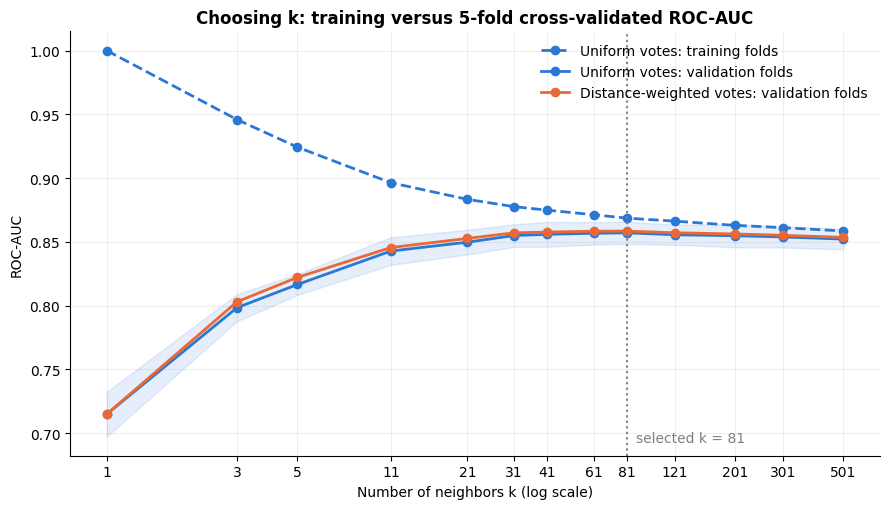

In [18]:
K_CURVE = [1, 3, 5, 11, 21, 31, 41, 61, 81, 121, 201, 301, 501]
X_final_train = X_train_pools[final_pool]

k_curve_rows = []
for weighting in ["uniform", "distance"]:
    curve_pipeline = make_selection_knn_pipeline(reduced_model2_features).set_params(
        **{**best_params, "classifier__weights": weighting}
    )
    train_scores, valid_scores = validation_curve(
        curve_pipeline,
        X_final_train,
        y_train,
        param_name="classifier__n_neighbors",
        param_range=K_CURVE,
        cv=tuning_cv,
        scoring="roc_auc",
        n_jobs=-1,
    )
    k_curve_rows.append(pd.DataFrame({
        "weights": weighting,
        "k": K_CURVE,
        "train_ROC_AUC": train_scores.mean(axis=1),
        "CV_ROC_AUC": valid_scores.mean(axis=1),
        "SD_CV_ROC_AUC": valid_scores.std(axis=1),
    }))
k_curve = pd.concat(k_curve_rows, ignore_index=True)
k_curve["train_minus_CV"] = k_curve["train_ROC_AUC"] - k_curve["CV_ROC_AUC"]
print(k_curve.round(4).to_string(index=False))

uniform_curve = k_curve[k_curve["weights"].eq("uniform")]
distance_curve = k_curve[k_curve["weights"].eq("distance")]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(uniform_curve["k"], uniform_curve["train_ROC_AUC"], marker="o", linestyle="--", linewidth=2, color=PRIMARY_COLOR, label="Uniform votes: training folds")
ax.plot(uniform_curve["k"], uniform_curve["CV_ROC_AUC"], marker="o", linewidth=2, color=PRIMARY_COLOR, label="Uniform votes: validation folds")
ax.fill_between(
    uniform_curve["k"],
    uniform_curve["CV_ROC_AUC"] - uniform_curve["SD_CV_ROC_AUC"],
    uniform_curve["CV_ROC_AUC"] + uniform_curve["SD_CV_ROC_AUC"],
    color=PRIMARY_COLOR,
    alpha=0.12,
)
ax.plot(distance_curve["k"], distance_curve["CV_ROC_AUC"], marker="o", linewidth=2, color=SECONDARY_COLOR, label="Distance-weighted votes: validation folds")
ax.axvline(selected_k, color="gray", linestyle=":", linewidth=1.5)
ax.annotate(
    f"selected k = {selected_k}",
    xy=(selected_k, ax.get_ylim()[0]),
    xytext=(6, 10),
    textcoords="offset points",
    color="gray",
)
ax.set_xscale("log")
ax.set_xticks(K_CURVE, [str(k) for k in K_CURVE])
ax.minorticks_off()
ax.set(
    title="Choosing k: training versus 5-fold cross-validated ROC-AUC",
    xlabel="Number of neighbors k (log scale)",
    ylabel="ROC-AUC",
)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 7. Outreach capacity threshold

PHAC cannot contact everyone, so outreach is framed as a capacity decision: contact the respondents with the highest predicted probability of no booster. Using the nested outer-fold (out-of-fold) training probabilities, the table shows precision, recall and F1 for No at 5%, 10% and 20% contact capacity. Lift compares precision with the share of No in the training set, i.e. how many times more effective the list is than contacting people at random. The probability threshold for the prespecified 10% capacity is locked here, before the test set is scored.

In [19]:
outreach_oof_no_probability = 1 - nested_oof_probability
outreach_oof_actual_no = y_train_array == 0
baseline_no_rate = outreach_oof_actual_no.mean()
outreach_order = np.argsort(-outreach_oof_no_probability, kind="stable")

outreach_rows = []
for capacity_rate in [0.05, 0.10, 0.20]:
    contact_count = int(np.ceil(capacity_rate * len(y_train)))
    contacted = np.zeros(len(y_train), dtype=bool)
    contacted[outreach_order[:contact_count]] = True
    precision_no = precision_score(outreach_oof_actual_no, contacted, zero_division=0)
    outreach_rows.append({
        "capacity_pct": capacity_rate * 100,
        "no_probability_threshold": outreach_oof_no_probability[outreach_order[contact_count - 1]],
        "contacted_n": int(contacted.sum()),
        "precision_no": precision_no,
        "lift_vs_random": precision_no / baseline_no_rate,
        "recall_no": recall_score(outreach_oof_actual_no, contacted, zero_division=0),
        "f1_no": f1_score(outreach_oof_actual_no, contacted, zero_division=0),
    })
outreach_oof_table = pd.DataFrame(outreach_rows)
outreach_threshold = float(
    outreach_oof_table.loc[outreach_oof_table["capacity_pct"].eq(10), "no_probability_threshold"].iloc[0]
)
print(f"Share of No in the training set (random-contact precision): {baseline_no_rate:.4f}")
print("\nNested outer-OOF no-booster outreach tradeoff:")
print(outreach_oof_table.round(4).to_string(index=False))
print(f"\nLocked outreach threshold for the 10% capacity target: {outreach_threshold:.4f}")

Share of No in the training set (random-contact precision): 0.4330

Nested outer-OOF no-booster outreach tradeoff:
 capacity_pct  no_probability_threshold  contacted_n  precision_no  lift_vs_random  recall_no  f1_no
          5.0                    0.9290          226        0.9690          2.2379     0.1124 0.2014
         10.0                    0.8624          451        0.9446          2.1814     0.2186 0.3550
         20.0                    0.6874          901        0.8990          2.0761     0.4156 0.5684

Locked outreach threshold for the 10% capacity target: 0.8624


## 8. Final locked-model test evaluation

The predictor pool and k-NN settings were locked with training-only CV (Section 5) and the outreach threshold with training out-of-fold probabilities (Section 7). Imputation, encoding, scaling and L1 selection remain inside the fitted pipeline. The locked model is evaluated once on the reserved test rows. Variables, preprocessing, threshold and hyperparameters are not revised based on these results.

**Which measure matters most.** ROC-AUC measures how well the model ranks respondents regardless of the cut-off and is used to compare models. For the outreach decision the class of interest is **No**. With a fixed outreach capacity, **precision for No** matters most: it is the share of contacted people who actually lack a booster, so it determines how much outreach effort is wasted on people who are already boosted. Recall for No (the share of all unboosted respondents reached) is reported alongside it to show coverage. The confusion matrix and classification report use the default 0.5 probability cut-off; the outreach results use the locked 10% capacity threshold.

In [20]:
locked_model2 = reduced_model2_search.best_estimator_
encoded_feature_count = len(
    locked_model2.named_steps["preprocess"].get_feature_names_out()
)
selected_count = int(locked_model2.named_steps["selector"].get_support().sum())
print(f"Input predictor variables: {len(reduced_model2_features)}")
print(f"Encoded columns before selection: {encoded_feature_count}")
print(f"Selected encoded features: {selected_count}")

X_model2_test = test_data[reduced_model2_features].copy()
y_model2_test = test_data["vac_boost_1"].eq("Yes").astype(int)
model2_test_probability = locked_model2.predict_proba(X_model2_test)[:, 1]
model2_test_prediction = locked_model2.predict(X_model2_test)
model2_test_no_probability = 1 - model2_test_probability
model2_test_outreach = model2_test_no_probability >= outreach_threshold
y_model2_test_no = y_model2_test.eq(0)

model2_test_accuracy = accuracy_score(y_model2_test, model2_test_prediction)
model2_test_auc = roc_auc_score(y_model2_test, model2_test_probability)
model2_test_confusion = confusion_matrix(
    y_model2_test, model2_test_prediction, labels=[0, 1]
)
model2_test_report = classification_report(
    y_model2_test,
    model2_test_prediction,
    labels=[0, 1],
    target_names=["No", "Yes"],
    digits=4,
    output_dict=True,
)
print(f"\nFinal test accuracy: {model2_test_accuracy:.4f}")
print(f"Final test ROC-AUC: {model2_test_auc:.4f}")
print("\nConfusion matrix (rows = actual No/Yes; columns = predicted No/Yes):")
print(model2_test_confusion)
print("\nClassification report:")
print(pd.DataFrame(model2_test_report).T.round(4).to_string())

test_precision_no_outreach = precision_score(y_model2_test_no, model2_test_outreach, zero_division=0)
print("\nReserved-test outreach results at the training-OOF threshold:")
print(pd.Series({
    "no_probability_threshold": outreach_threshold,
    "contacted_n": int(model2_test_outreach.sum()),
    "contact_rate": model2_test_outreach.mean(),
    "precision_no": test_precision_no_outreach,
    "lift_vs_random": test_precision_no_outreach / y_model2_test_no.mean(),
    "recall_no": recall_score(y_model2_test_no, model2_test_outreach, zero_division=0),
    "f1_no": f1_score(y_model2_test_no, model2_test_outreach, zero_division=0),
}).round(4).to_string())

Input predictor variables: 120
Encoded columns before selection: 496
Selected encoded features: 89

Final test accuracy: 0.7745
Final test ROC-AUC: 0.8500

Confusion matrix (rows = actual No/Yes; columns = predicted No/Yes):
[[540 295]
 [140 954]]

Classification report:
              precision  recall  f1-score    support
No               0.7941  0.6467    0.7129   835.0000
Yes              0.7638  0.8720    0.8143  1094.0000
accuracy         0.7745  0.7745    0.7745     0.7745
macro avg        0.7790  0.7594    0.7636  1929.0000
weighted avg     0.7769  0.7745    0.7704  1929.0000

Reserved-test outreach results at the training-OOF threshold:
no_probability_threshold      0.8624
contacted_n                 180.0000
contact_rate                  0.0933
precision_no                  0.9722
lift_vs_random                2.2460
recall_no                     0.2096
f1_no                         0.3448


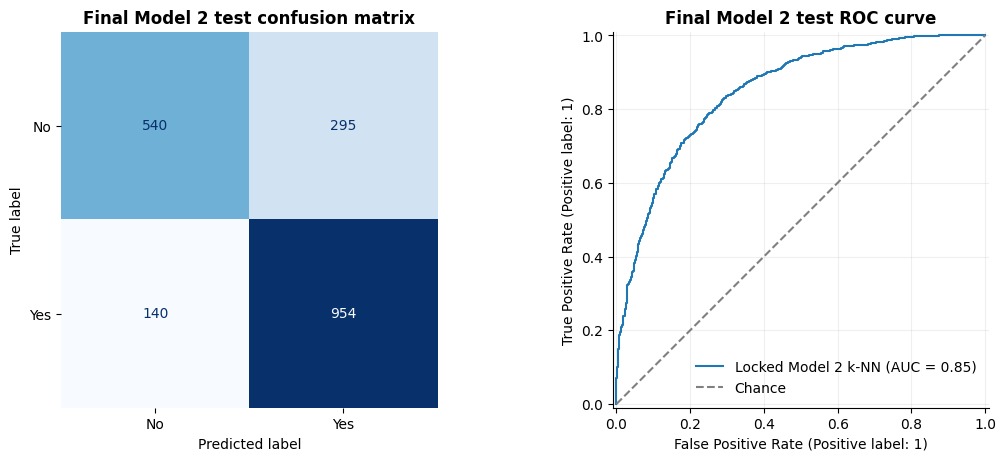

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
ConfusionMatrixDisplay(
    confusion_matrix=model2_test_confusion,
    display_labels=["No", "Yes"],
).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Final Model 2 test confusion matrix")
axes[0].grid(False)
for spine in axes[0].spines.values():
    spine.set_visible(False)
RocCurveDisplay.from_predictions(
    y_model2_test,
    model2_test_probability,
    name="Locked Model 2 k-NN",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[1].set_title("Final Model 2 test ROC curve")
axes[1].legend(loc="lower right", frameon=False)
plt.show()

In [22]:
final_model2_summary = pd.DataFrame([{
    "model": "Final Model 2",
    "predictor_pool": final_pool,
    "k": selected_k,
    "weights": best_params["classifier__weights"],
    "distance": "Manhattan" if best_params["classifier__p"] == 1 else "Euclidean",
    "L1_C": selected_C,
    "input_predictor_variables": len(reduced_model2_features),
    "encoded_columns_before_selection": encoded_feature_count,
    "selected_encoded_features": selected_count,
    "test_ROC_AUC": model2_test_auc,
    "test_accuracy": model2_test_accuracy,
    "test_precision_No": model2_test_report["No"]["precision"],
    "test_recall_No": model2_test_report["No"]["recall"],
    "test_F1_No": model2_test_report["No"]["f1-score"],
    "test_precision_Yes": model2_test_report["Yes"]["precision"],
    "test_recall_Yes": model2_test_report["Yes"]["recall"],
    "test_F1_Yes": model2_test_report["Yes"]["f1-score"],
}])
print(final_model2_summary.round(4).T.to_string(header=False))

model                                                Final Model 2
predictor_pool                    Expanded eligible predictor pool
k                                                               81
weights                                                   distance
distance                                                 Manhattan
L1_C                                                           0.1
input_predictor_variables                                      120
encoded_columns_before_selection                               496
selected_encoded_features                                       89
test_ROC_AUC                                                  0.85
test_accuracy                                               0.7745
test_precision_No                                           0.7941
test_recall_No                                              0.6467
test_F1_No                                                  0.7129
test_precision_Yes                                          0.

## 9. Who the outreach list reaches

The locked 10% outreach list on the test set is described by booster status and by respondent group. This shows whether the list mainly reaches never-vaccinated respondents (who need confidence-building communication) or vaccinated respondents without a booster (who need reminders and access support), and which groups PHAC would be contacting. This is a description of the already locked model and is not used to change it.

Outreach list (10% capacity) by booster status, test set:
                        test_n  contacted_n  share_of_outreach_list_pct  share_of_group_reached_pct
booster_status                                                                                     
Boosted                   1094            5                         2.8                         0.5
Vaccinated, no booster     641           65                        36.1                        10.1
Never vaccinated           194          110                        61.1                        56.7

Composition by age group (% of all test respondents vs % of the outreach list):
           all_test_pct  outreach_list_pct  difference_pp
age_group                                                
18–29              17.8               18.3            0.6
30–39              16.4               23.3            6.9
40–49              14.0               25.6           11.5
50–59              15.0               13.9           -1.1
60–69        

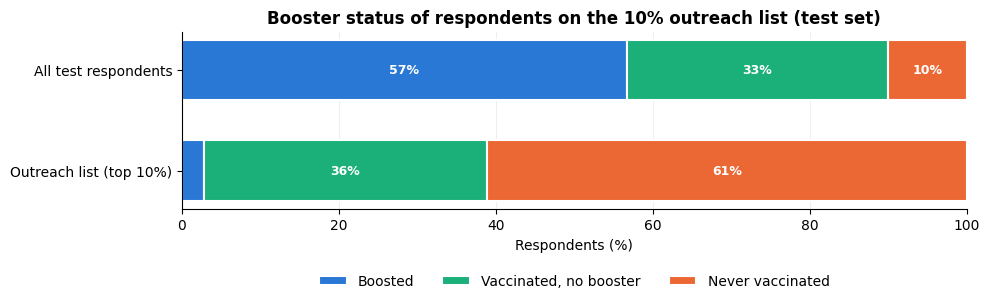

In [23]:
test_profile = pd.DataFrame({
    "booster_status": booster_status.loc[test_data.index],
    "age_group": pd.cut(test_data["age"], bins=AGE_BINS, labels=AGE_LABELS),
    "vaccine_trust": test_data["vac7"],
    "province": test_data["region"].str.split(" / ").str[0],
    "on_outreach_list": model2_test_outreach,
})

status_reach = test_profile.groupby("booster_status")["on_outreach_list"].agg(test_n="size", contacted_n="sum")
status_reach = status_reach.reindex(STATUS_ORDER)
status_reach["share_of_outreach_list_pct"] = status_reach["contacted_n"] / status_reach["contacted_n"].sum() * 100
status_reach["share_of_group_reached_pct"] = status_reach["contacted_n"] / status_reach["test_n"] * 100
print("Outreach list (10% capacity) by booster status, test set:")
print(status_reach.round(1).to_string())


def list_composition(column, order=None):
    composition = pd.DataFrame({
        "all_test_pct": test_profile[column].value_counts(normalize=True) * 100,
        "outreach_list_pct": test_profile.loc[test_profile["on_outreach_list"], column].value_counts(normalize=True) * 100,
    }).fillna(0)
    if order is not None:
        composition = composition.reindex(order)
    else:
        composition = composition.sort_values("outreach_list_pct", ascending=False)
    composition["difference_pp"] = composition["outreach_list_pct"] - composition["all_test_pct"]
    return composition


for column, order in [
    ("age_group", AGE_LABELS),
    ("vaccine_trust", ["Not at all", "A little", "Moderately", "Very much"]),
    ("province", None),
]:
    print(f"\nComposition by {column.replace('_', ' ')} (% of all test respondents vs % of the outreach list):")
    print(list_composition(column, order).round(1).to_string())

composition_plot = pd.DataFrame({
    "All test respondents": test_profile["booster_status"].value_counts(normalize=True),
    "Outreach list (top 10%)": test_profile.loc[test_profile["on_outreach_list"], "booster_status"].value_counts(normalize=True),
}).T.reindex(columns=STATUS_ORDER).fillna(0) * 100

fig, ax = plt.subplots(figsize=(10, 3.4))
left = np.zeros(len(composition_plot))
for status in STATUS_ORDER:
    values = composition_plot[status].to_numpy()
    bars = ax.barh(composition_plot.index, values, left=left, color=STATUS_COLORS[status], edgecolor="white", linewidth=1.5, height=0.6, label=status)
    ax.bar_label(bars, labels=[f"{value:.0f}%" if value >= 6 else "" for value in values], label_type="center", color="white", fontsize=9, fontweight="bold")
    left += values
ax.invert_yaxis()
ax.set(title="Booster status of respondents on the 10% outreach list (test set)", xlabel="Respondents (%)", xlim=(0, 100))
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)
fig.tight_layout()
plt.show()